# Six-feature holdout importance

Measure how the six retained inputs contribute to the six evaluation pipelines on the untouched 2026 holdout. Individual permutation importance reports each model column; grouped permutation importance treats the two layoff flags as one conceptual family.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import brier_score_loss, log_loss

RANDOM_SEED = 42
N_REPEATS = 15
WORKING_DIR = Path.cwd().resolve()
RESEARCH_DIR = WORKING_DIR if WORKING_DIR.name == "research" else WORKING_DIR / "research"
if not RESEARCH_DIR.is_dir():
    raise FileNotFoundError(
        "Run this notebook from the project root or the research directory."
    )

HOLDOUT_PATH = RESEARCH_DIR / "data" / "output" / "model_test_2026.csv"
MODEL_DIR = RESEARCH_DIR / "models" / "holdout_2026"
MANIFEST_PATH = RESEARCH_DIR / "models" / "model_manifest.csv"
FEATURE_COLUMNS = [
    "GlobalEloDiff",
    "SurfaceEloDiff",
    "RankDiff",
    "Player1LayoffOver6Months",
    "Player2LayoffOver6Months",
    "MatchesLast7DaysDiff",
]
MODEL_FILENAMES = {
    "Decision Tree": "decision_tree.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib",
    "LightGBM": "lightgbm.joblib",
    "Logistic Regression": "logistic_regression.joblib",
    "Simple Neural Net": "simple_neural_net.joblib",
}

holdout_data = pd.read_csv(HOLDOUT_PATH, parse_dates=["Date"], low_memory=False)
for column in ["Player1LayoffOver6Months", "Player2LayoffOver6Months"]:
    holdout_data[column] = (
        holdout_data[column]
        .astype("string")
        .map({"True": 1.0, "False": 0.0})
        .astype(float)
    )
for column in FEATURE_COLUMNS:
    holdout_data[column] = pd.to_numeric(holdout_data[column], errors="coerce")

X_holdout = holdout_data[FEATURE_COLUMNS].copy()
y_holdout = pd.to_numeric(holdout_data["Player1Won"], errors="raise").astype("int8")
models = {
    model_name: joblib.load(MODEL_DIR / filename)
    for model_name, filename in MODEL_FILENAMES.items()
}
manifest = pd.read_csv(MANIFEST_PATH)

assert len(FEATURE_COLUMNS) == 6
assert X_holdout.columns.tolist() == FEATURE_COLUMNS
assert holdout_data["Date"].dt.year.eq(2026).all()
assert set(y_holdout.unique()).issubset({0, 1})
assert set(models) == set(MODEL_FILENAMES)
for model_name, model in models.items():
    assert list(model.feature_names_in_) == FEATURE_COLUMNS, model_name
assert manifest["FeatureCount"].eq(6).all()
assert manifest["FeatureList"].eq("|".join(FEATURE_COLUMNS)).all()

print(f"Holdout rows: {len(holdout_data):,}")
print(f"Date range: {holdout_data['Date'].min():%Y-%m-%d} to {holdout_data['Date'].max():%Y-%m-%d}")
print(f"Features ({len(FEATURE_COLUMNS)}): {FEATURE_COLUMNS}")

Holdout rows: 1,822
Date range: 2026-01-04 to 2026-08-14
Features (6): ['GlobalEloDiff', 'SurfaceEloDiff', 'RankDiff', 'Player1LayoffOver6Months', 'Player2LayoffOver6Months', 'MatchesLast7DaysDiff']


## Holdout baselines and individual permutation importance

A positive importance means shuffling that feature worsened 2026 Brier score. The saved evaluation models were trained only through 2025.

In [2]:
def positive_probability(model, features: pd.DataFrame) -> np.ndarray:
    classes = np.asarray(model.classes_)
    positive_indices = np.flatnonzero(classes == 1)
    assert len(positive_indices) == 1
    probabilities = np.asarray(model.predict_proba(features))[
        :, int(positive_indices[0])
    ]
    assert probabilities.shape == (len(features),)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0.0) & (probabilities <= 1.0)).all()
    return probabilities


baseline_rows = []
individual_rows = []
for model_name, model in models.items():
    probabilities = positive_probability(model, X_holdout)
    baseline_brier = brier_score_loss(y_holdout, probabilities)
    baseline_log_loss = log_loss(y_holdout, probabilities, labels=[0, 1])
    baseline_rows.append(
        {
            "Model": model_name,
            "BrierScore": baseline_brier,
            "LogLoss": baseline_log_loss,
        }
    )

    result = permutation_importance(
        model,
        X_holdout,
        y_holdout,
        scoring="neg_brier_score",
        n_repeats=N_REPEATS,
        random_state=RANDOM_SEED,
        n_jobs=1,
    )
    individual_rows.extend(
        {
            "Model": model_name,
            "Feature": feature,
            "MeanBrierIncrease": float(mean_importance),
            "RepeatSD": float(std_importance),
        }
        for feature, mean_importance, std_importance in zip(
            FEATURE_COLUMNS,
            result.importances_mean,
            result.importances_std,
        )
    )
    print(f"Finished {model_name}")

baseline_scores = pd.DataFrame(baseline_rows).sort_values("BrierScore")
individual_importance = pd.DataFrame(individual_rows)
individual_summary = (
    individual_importance.groupby("Feature", as_index=False)
    .agg(
        MeanAcrossModels=("MeanBrierIncrease", "mean"),
        MedianAcrossModels=("MeanBrierIncrease", "median"),
        PositiveModels=("MeanBrierIncrease", lambda values: int((values > 0).sum())),
    )
    .sort_values("MeanAcrossModels", ascending=False)
    .reset_index(drop=True)
)

manifest_scores = manifest.set_index("Model")["HoldoutBrierScore"]
for row in baseline_scores.itertuples(index=False):
    assert np.isclose(row.BrierScore, manifest_scores.loc[row.Model], atol=1e-12)

display(baseline_scores)
display(individual_summary)

Finished Decision Tree


Finished Random Forest


Finished XGBoost


/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Finished LightGBM
Finished Logistic Regression


Finished Simple Neural Net


,Model,BrierScore,LogLoss
5,Simple Neural Net,0.214618,0.616750
4,Logistic Regression,0.215355,0.618070
2,XGBoost,0.216206,0.620670
1,Random Forest,0.217335,0.623148
3,LightGBM,0.217552,0.624291
0,Decision Tree,0.225548,0.701279


,Feature,MeanAcrossModels,MedianAcrossModels,PositiveModels
0,GlobalEloDiff,0.018455,0.018466,6
1,SurfaceEloDiff,0.007502,0.007297,6
2,RankDiff,0.005863,0.006236,6
3,MatchesLast7DaysDiff,0.000863,0.000856,6
4,Player2LayoffOver6Months,0.000164,0.000179,4
5,Player1LayoffOver6Months,0.000065,0.000044,4


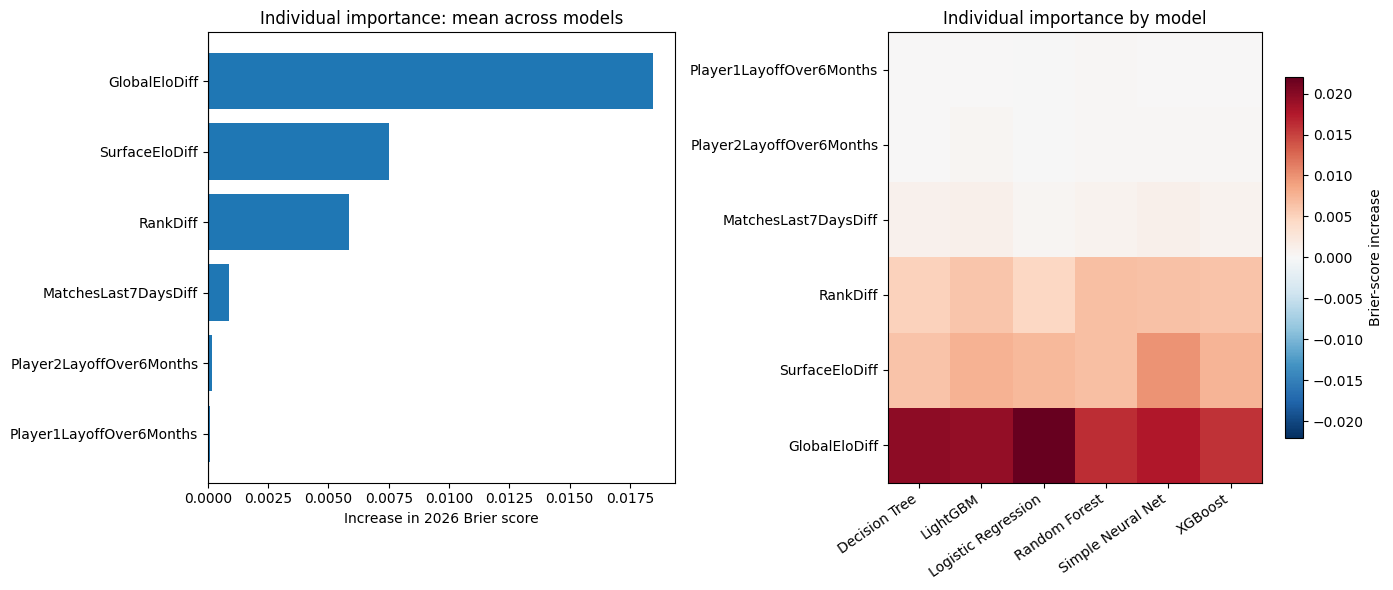

In [3]:
plot_data = individual_summary.set_index("Feature").sort_values("MeanAcrossModels")
importance_matrix = individual_importance.pivot(
    index="Feature",
    columns="Model",
    values="MeanBrierIncrease",
).loc[plot_data.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(plot_data.index, plot_data["MeanAcrossModels"])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Individual importance: mean across models")
axes[0].set_xlabel("Increase in 2026 Brier score")

heat_limit = max(float(np.abs(importance_matrix.to_numpy()).max()), 1e-12)
heatmap = axes[1].imshow(
    importance_matrix,
    aspect="auto",
    cmap="RdBu_r",
    vmin=-heat_limit,
    vmax=heat_limit,
)
axes[1].set_yticks(np.arange(len(importance_matrix.index)), labels=importance_matrix.index)
axes[1].set_xticks(
    np.arange(len(importance_matrix.columns)),
    labels=importance_matrix.columns,
    rotation=35,
    ha="right",
)
axes[1].set_title("Individual importance by model")
fig.colorbar(heatmap, ax=axes[1], label="Brier-score increase", shrink=0.8)
fig.tight_layout()
plt.show()

## Concept-level grouped importance

Shuffle the two layoff flags together with the same row permutation so layoff is measured as one feature family. The other compact concepts each contain one model column.

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/nick/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

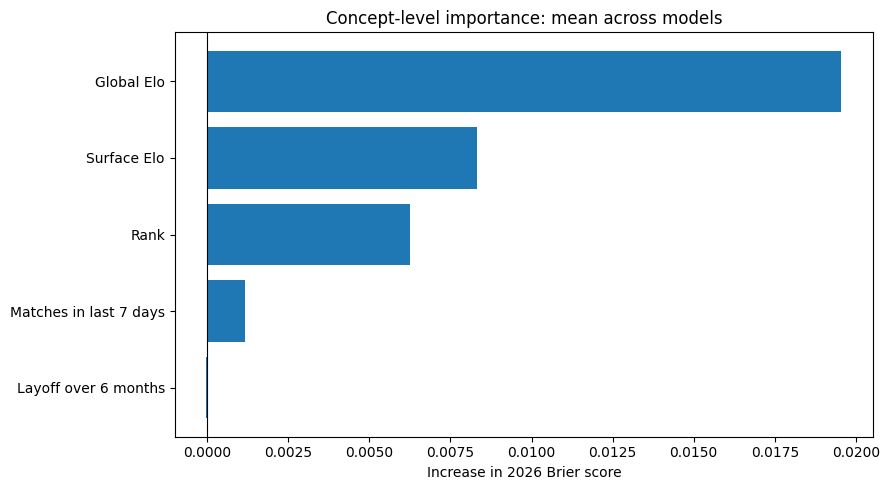

,Group,MeanAcrossModels,MedianAcrossModels,PositiveModels
0,Global Elo,0.019551,0.019428,6
1,Surface Elo,0.008323,0.007952,6
2,Rank,0.006244,0.006641,6
3,Matches in last 7 days,0.001172,0.001068,6
4,Layoff over 6 months,-0.000019,-0.000015,2


,Model,Group,MeanBrierIncrease,RepeatSD
18,LightGBM,Layoff over 6 months,0.000072,0.000639
8,Random Forest,Layoff over 6 months,0.000026,0.000366
3,Decision Tree,Layoff over 6 months,0.000000,0.000000
28,Simple Neural Net,Layoff over 6 months,-0.000031,0.000445
13,XGBoost,Layoff over 6 months,-0.000082,0.000493
23,Logistic Regression,Layoff over 6 months,-0.000103,0.000212


In [4]:
FEATURE_GROUPS = {
    "Global Elo": ["GlobalEloDiff"],
    "Surface Elo": ["SurfaceEloDiff"],
    "Rank": ["RankDiff"],
    "Layoff over 6 months": [
        "Player1LayoffOver6Months",
        "Player2LayoffOver6Months",
    ],
    "Matches in last 7 days": ["MatchesLast7DaysDiff"],
}
assert [column for columns in FEATURE_GROUPS.values() for column in columns] == FEATURE_COLUMNS


def grouped_importance_for_model(model_name: str, model) -> pd.DataFrame:
    baseline_probabilities = positive_probability(model, X_holdout)
    baseline_brier = brier_score_loss(y_holdout, baseline_probabilities)
    rng = np.random.default_rng(RANDOM_SEED)
    rows = []

    for group_name, columns in FEATURE_GROUPS.items():
        repeat_importances = []
        for _ in range(N_REPEATS):
            permutation = rng.permutation(len(X_holdout))
            shuffled = X_holdout.copy()
            for column in columns:
                shuffled[column] = X_holdout.iloc[permutation][column].to_numpy()
            probabilities = positive_probability(model, shuffled)
            repeat_importances.append(
                brier_score_loss(y_holdout, probabilities) - baseline_brier
            )
        rows.append(
            {
                "Model": model_name,
                "Group": group_name,
                "MeanBrierIncrease": float(np.mean(repeat_importances)),
                "RepeatSD": float(np.std(repeat_importances, ddof=1)),
            }
        )
    return pd.DataFrame(rows)


grouped_importance = pd.concat(
    [grouped_importance_for_model(name, model) for name, model in models.items()],
    ignore_index=True,
)
grouped_summary = (
    grouped_importance.groupby("Group", as_index=False)
    .agg(
        MeanAcrossModels=("MeanBrierIncrease", "mean"),
        MedianAcrossModels=("MeanBrierIncrease", "median"),
        PositiveModels=("MeanBrierIncrease", lambda values: int((values > 0).sum())),
    )
    .sort_values("MeanAcrossModels", ascending=False)
    .reset_index(drop=True)
)

group_plot = grouped_summary.set_index("Group").sort_values("MeanAcrossModels")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(group_plot.index, group_plot["MeanAcrossModels"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Concept-level importance: mean across models")
ax.set_xlabel("Increase in 2026 Brier score")
fig.tight_layout()
plt.show()

display(grouped_summary)
display(
    grouped_importance.loc[
        grouped_importance["Group"].eq("Layoff over 6 months")
    ].sort_values("MeanBrierIncrease", ascending=False)
)

In [5]:
OUTPUT_DIR = RESEARCH_DIR / "models"
individual_path = OUTPUT_DIR / "feature_importance_individual.csv"
grouped_path = OUTPUT_DIR / "feature_importance_grouped.csv"
individual_importance.to_csv(individual_path, index=False)
grouped_importance.to_csv(grouped_path, index=False)

assert len(individual_importance) == len(models) * len(FEATURE_COLUMNS)
assert len(grouped_importance) == len(models) * len(FEATURE_GROUPS)
assert set(individual_importance["Feature"]) == set(FEATURE_COLUMNS)
assert set(grouped_importance["Group"]) == set(FEATURE_GROUPS)
assert individual_path.resolve().parent == OUTPUT_DIR.resolve()
assert grouped_path.resolve().parent == OUTPUT_DIR.resolve()

top_feature = individual_summary.iloc[0]
top_group = grouped_summary.iloc[0]
layoff_group = grouped_summary.loc[
    grouped_summary["Group"].eq("Layoff over 6 months")
].iloc[0]
print(
    f"Top individual feature: {top_feature['Feature']} "
    f"({top_feature['MeanAcrossModels']:.6f} mean Brier increase)."
)
print(
    f"Top concept: {top_group['Group']} "
    f"({top_group['MeanAcrossModels']:.6f} mean Brier increase)."
)
print(
    f"Grouped layoff importance: {layoff_group['MeanAcrossModels']:.6f}; "
    f"positive for {int(layoff_group['PositiveModels'])}/{len(models)} models."
)
print(f"Saved individual results to {individual_path.resolve()}")
print(f"Saved grouped results to {grouped_path.resolve()}")

Top individual feature: GlobalEloDiff (0.018455 mean Brier increase).
Top concept: Global Elo (0.019551 mean Brier increase).
Grouped layoff importance: -0.000019; positive for 2/6 models.
Saved individual results to /Users/nick/Desktop/tennis live/research/models/feature_importance_individual.csv
Saved grouped results to /Users/nick/Desktop/tennis live/research/models/feature_importance_grouped.csv


## Interpretation notes

- Importance is measured out of sample on 2026 using models trained only through 2025.
- A positive value means permutation worsened probability accuracy; small negative values can arise from sampling noise or an unhelpful feature.
- Correlated global and surface Elo differences can substitute for each other, so permutation importance can understate their combined value.
- The two layoff columns are interpreted primarily through the grouped result.
- Importance measures predictive reliance, not causality. The final all-data models are intentionally not used for this analysis.